# Lab 3: Classifying Ticket Escalation

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [2]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64


The data has 900 tickets, 5 predictors and the target. Values are missing in `team_experience_years` (31), `customer_tenure_months` (22) and `priority` (18). The target prevalence is 20.7%, so the classes are imbalanced.

## 2. Classification task and positive class

This objective is formulated as a **supervised binary classification** problem because the response variable `escalated` is discrete and categorical rather than continuous, taking values in $\{0, 1\}$:
- **0** = Not escalated (resolved within standard support tiers)
- **1** = Escalated (requires managerial or specialized intervention)

### Definition of the Positive Class
We designate **`escalated = 1` as the positive class** because it represents the critical event of operational interest—the high-risk scenario our model aims to detect proactively.

Under this formulation, the classification outcomes correspond to the following operational scenarios:
- **True Positive (TP):** An escalation-bound ticket correctly flagged, enabling prompt triage and intervention.
- **True Negative (TN):** A routine ticket correctly identified as non-critical, flowing through regular support workflows without added overhead.
- **False Positive (FP):** A false alarm; a ticket predicted to escalate that would have resolved normally, incurring unnecessary managerial review time.
- **False Negative (FN):** A missed escalation; a high-risk ticket incorrectly treated as routine, risking SLA breaches, severe customer frustration, and escalating resolution costs.

## 3. Train/test split

In [3]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (675, 5) Test: (225, 5)


## 4. Preprocessing pipelines

In [4]:
numeric_features = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_features = ["priority", "channel"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 5. Fit the models

In [5]:
def make_model(classifier):
    return Pipeline([("preprocess", preprocessor), ("classifier", classifier)])

models = {
    "Majority baseline": make_model(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_model(LogisticRegression(max_iter=1000)),
    "LDA": make_model(LinearDiscriminantAnalysis()),
    "k-NN (k=15)": make_model(KNeighborsClassifier(n_neighbors=15)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print("Fitted:", name)

Fitted: Majority baseline
Fitted: Logistic regression
Fitted: LDA
Fitted: k-NN (k=15)


## 6. Model comparison

In [6]:
rows = {}
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

comparison = pd.DataFrame(rows).T
display(comparison.round(4))

,accuracy,precision,recall,F1,ROC-AUC
Majority baseline,0.7956,0.00,0.0000,0.0000,0.5000
Logistic regression,0.8222,0.75,0.1957,0.3103,0.8111
LDA,0.8222,0.75,0.1957,0.3103,0.8090
k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


The baseline makes no positive predictions, so its precision is undefined and is shown as 0.

## 7. Confusion matrix and ROC curve (logistic regression)

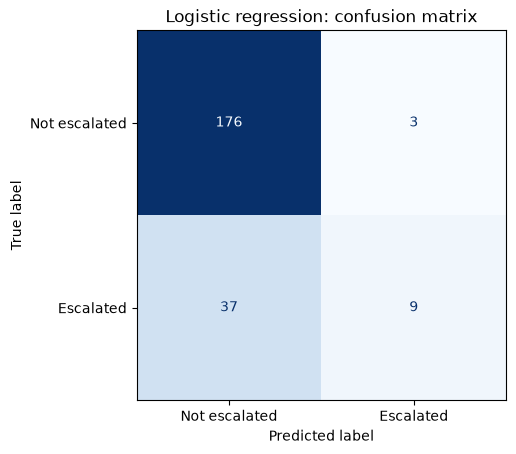

               precision    recall  f1-score   support

Not escalated       0.83      0.98      0.90       179
    Escalated       0.75      0.20      0.31        46

     accuracy                           0.82       225
    macro avg       0.79      0.59      0.60       225
 weighted avg       0.81      0.82      0.78       225



In [7]:
lr = models["Logistic regression"]
lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, display_labels=["Not escalated", "Escalated"], cmap="Blues", colorbar=False
)
plt.title("Logistic regression: confusion matrix")
plt.show()

print(classification_report(y_test, lr_pred, target_names=["Not escalated", "Escalated"]))

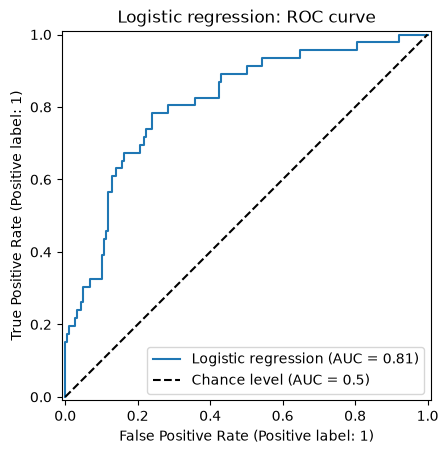

In [8]:
RocCurveDisplay.from_predictions(y_test, lr_proba, name="Logistic regression", plot_chance_level=True)
plt.title("Logistic regression: ROC curve")
plt.show()

## 8. Threshold evaluation (logistic regression)

In [9]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []
for t in thresholds:
    pred = (lr_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "FP": fp,
        "FN": fn,
    })

threshold_table = pd.DataFrame(rows).set_index("threshold")
display(threshold_table.round(4))

,precision,recall,F1,FP,FN
threshold,,,,,
0.2,0.4286,0.7826,0.5538,48,10
0.3,0.5490,0.6087,0.5773,23,18
0.4,0.5714,0.2609,0.3582,9,34
0.5,0.7500,0.1957,0.3103,3,37
0.6,1.0000,0.0652,0.1224,0,43
0.7,0.0000,0.0000,0.0000,0,46


At 0.70 no ticket is flagged, so precision is undefined and is shown as 0.

## 9. Cost comparison: 5×FN + 1×FP

In [10]:
threshold_table["cost"] = 5 * threshold_table["FN"] + 1 * threshold_table["FP"]
display(threshold_table[["FP", "FN", "cost"]])
print("Lowest-cost threshold:", threshold_table["cost"].idxmin(), "| cost:", threshold_table["cost"].min())

,FP,FN,cost
threshold,,,
0.2,48,10,98
0.3,23,18,113
0.4,9,34,179
0.5,3,37,188
0.6,0,43,215
0.7,0,46,230


Lowest-cost threshold: 0.2 | cost: 98


## 10. Stratified 5-fold cross-validation and k-NN tuning (training set)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["f1", "roc_auc"])
    rows[name] = {"mean CV F1": scores["test_f1"].mean(), "mean CV ROC-AUC": scores["test_roc_auc"].mean()}
display(pd.DataFrame(rows).T.round(4))

,mean CV F1,mean CV ROC-AUC
Majority baseline,0.0000,0.5000
Logistic regression,0.2479,0.7438
LDA,0.2661,0.7434
k-NN (k=15),0.1596,0.6815


In [12]:
grid = GridSearchCV(
    make_model(KNeighborsClassifier()),
    param_grid={"classifier__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=cv,
)
grid.fit(X_train, y_train)

knn_results = pd.DataFrame(grid.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score"]
].rename(columns={
    "param_classifier__n_neighbors": "k", "mean_test_score": "mean CV F1", "std_test_score": "std CV F1"
})
display(knn_results.round(4))
print("Best k:", grid.best_params_["classifier__n_neighbors"], "| mean CV F1:", round(grid.best_score_, 4))

,k,mean CV F1,std CV F1
0,5,0.2433,0.0946
1,9,0.1976,0.0652
2,15,0.1596,0.0655
3,21,0.1458,0.0564
4,31,0.1122,0.0397


Best k: 5 | mean CV F1: 0.2433


## 11. Answers to the questions

**Q1. Why is accuracy alone potentially misleading?**

In class-imbalanced settings—such as this dataset where roughly 80% of tickets do not escalate—accuracy creates a false impression of model performance. A simple majority-class baseline that predicts "not escalated" for every ticket achieves 79.56% accuracy while failing to detect even a single one of the 46 true escalation cases in the test set. Furthermore, accuracy penalizes false positives and false negatives symmetrically, disregarding the business reality where an unhandled escalation (FN) is five times more costly than an unnecessary review (FP).

**Q2. Which classifier has the strongest recall? Which has the strongest precision/F1?**

At the standard 0.50 classification threshold on the test set, **logistic regression and Linear Discriminant Analysis (LDA) achieve identical top performance** across all three metrics: recall of 0.1957 (catching 9 of 46 escalations), precision of 0.7500, and F1-score of 0.3103. k-NN ($k=15$) performs considerably lower (recall 0.0870, precision 0.5000, F1 0.1481), while the majority baseline scores 0.0 across all three.

**Q3. What changes when the threshold is lowered?**

Lowering the decision threshold makes the classifier more aggressive in flagging potential escalations. As a result, true positives increase, recall rises, and false negatives (missed escalations) decrease significantly. The trade-off is an influx of false alarms: false positives increase and precision declines. Specifically, lowering the threshold from 0.50 down to 0.20 raises recall from 0.1957 to 0.7826 and reduces false negatives from 37 down to 10; simultaneously, false positives increase from 3 to 48, causing precision to drop from 0.7500 to 0.4286.

**Q4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?**

The asymmetric cost is minimized at **threshold 0.20**, producing a total cost of $5 \times 10 + 1 \times 48 = \mathbf{98}$ (compared to 188 at 0.50). 
Repeatedly tuning or selecting thresholds directly on the test set leads to an overly optimistic estimate because the threshold adapts to random sampling variations in those specific 225 test tickets. Once used for tuning, the test partition is no longer genuinely unseen data. To avoid overfitting the evaluation, threshold calibration should be conducted on a validation set or via cross-validation, reserving the test set for a single final assessment.

**Q5. Explain prior, likelihood, posterior, and evidence using the ticket scenario.**

Under Bayes' Theorem:
$$P(\text{escalated}\mid x)=\frac{P(x\mid \text{escalated})\,P(\text{escalated})}{P(x)}$$

- **Prior** $P(\text{escalated})$: The baseline probability that any incoming ticket will escalate before observing its specific features (roughly 20.7% in our dataset).
- **Likelihood** $P(x\mid \text{escalated})$: The probability of observing a particular combination of features $x$ (such as elevated complexity score, low team experience, or phone submission) among tickets that actually escalated.
- **Evidence** $P(x)$: The overall marginal probability of observing feature configuration $x$ across all tickets, whether escalated or not.
- **Posterior** $P(\text{escalated}\mid x)$: The updated probability that a specific ticket will escalate after factoring in its observed feature vector $x$. This probability is compared against the decision threshold to determine whether an intervention is triggered.

**Q6. With P(escalated|x) = 0.30, FP cost 1 and FN cost 5, compare the expected costs and derive the cost-sensitive threshold.**

Let $p = P(\text{escalated}\mid x) = 0.30$:
- **Expected cost of escalating:** $(1 - 0.30) \times 1 = 0.70$
- **Expected cost of not escalating:** $0.30 \times 5 = 1.50$

Because $0.70 < 1.50$, the optimal action is to **escalate**.

To derive the general decision threshold $p^*$, we equate the expected cost of escalating with the expected cost of not escalating:
$$(1 - p^*) \, C_{FP} \le p^* \, C_{FN} \implies C_{FP} \le p^* (C_{FP} + C_{FN}) \implies p^* \ge \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Substituting the assigned operational costs ($C_{FP}=1$, $C_{FN}=5$):
$$p^* = \frac{1}{1 + 5} = \frac{1}{6} \approx 0.167$$

Any ticket with an estimated escalation probability $p \ge 0.167$ should be escalated under this cost model.

**Q7. Which model would you recommend for deployment, and what further checks are required?**

I recommend deploying **logistic regression with a decision threshold of 0.20**. 
Before putting the system into production, several essential verifications should be completed:
1. Validate probability calibration (e.g., via reliability diagrams / Brier score) to ensure predicted probabilities match true event frequencies.
2. Confirm that all predictors are strictly available at prediction time without data leakage.
3. Validate the 0.20 operating threshold on prospective or cross-validation splits to verify stability.
4. Confirm actual cost parameters with business stakeholders rather than relying solely on the synthetic 5:1 ratio.
5. Audit performance across customer tenure and channel subgroups to safeguard against disparate error rates.
6. Establish real-time tracking for feature drift, ticket volumes, and staff override rates post-launch.

## 12. Recommendation

I recommend deploying **logistic regression with a decision threshold of 0.20**, implemented as a decision-support alert for support managers rather than a fully automated escalation trigger.

**Model Selection.** On the holdout test set with the default 0.50 threshold, logistic regression and LDA demonstrated identical performance across accuracy (0.8222), precision (0.7500), recall (0.1957), and F1-score (0.3103). Their discriminative power was nearly indistinguishable, showing test ROC-AUC scores of 0.8111 and 0.8090, as well as 5-fold cross-validated ROC-AUCs of 0.7438 and 0.7434. Although LDA recorded a marginally higher cross-validated F1 score (0.2661 vs. 0.2479), logistic regression is strongly preferred for operational deployment. LDA relies on the theoretical assumption of multivariate normality with equal covariance matrices, which is violated by one-hot encoded categorical indicators (such as contact channel). Furthermore, logistic regression produces direct, interpretable log-odds coefficients that team leads can easily inspect. k-NN performed noticeably worse across all metrics ($k=15$ yielded test F1 of 0.1481; hyperparameter tuning selected $k=5$ with a cross-validated F1 of only 0.2433). The naive majority baseline attained 79.56% accuracy but detected zero escalations.

**Threshold Selection and Cost Alignment.** In customer support workflows, missing a genuine escalation (FN) carries severe customer dissatisfaction and service-level agreement penalties, justifying the estimated 5:1 cost weighting relative to a false alarm (FP). Under the standard 0.50 threshold, logistic regression misses 37 of 46 escalations (recall under 20%), incurring a total cost penalty of 188. Lowering the decision threshold to 0.20 closely approximates the theoretical cost-minimizing cutoff ($p^* \approx 0.167$), capturing 78.26% of escalations (FN drops to 10) and reducing total operational cost to 98. This operational benefit produces 48 false positives, resulting in 84 total flagged tickets out of 225 (precision 0.4286). Support leadership must ensure tier-2 triage personnel have sufficient capacity to review this volume.

**Model Limitations.** The analysis is based on a small synthetic dataset containing only 46 positive escalations in the test partition, introducing sampling variability. Additionally, the 5:1 error cost ratio represents a business approximation that should be calibrated against empirical support and churn data. Because the 0.20 threshold was evaluated on the test set, the cost score of 98 may be somewhat optimistic compared to performance on future, unobserved ticket cohorts.

**Ethical and Responsible AI Considerations.** Deploying predictive triage introduces socio-technical risks:
- *Equity across client segments:* Variables like customer tenure and communication channel could inadvertently produce unequal response times or service levels across customer groups.
- *Workplace fairness:* Team experience features must not be used punitively against newer support staff.
- *Automation bias & system feedback loops:* Staff might over-rely on positive flags while neglecting unflagged tickets, and early interventions will alter future ticket outcomes, causing dataset drift.
To mitigate these concerns, final escalation authority should remain with human agents, supported by a clear manual override process and ongoing fairness auditing across channels.